In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv(
    "../data/processed/cleaned_customer_data.csv"
)

sns.set_theme(style="whitegrid")

print("EDA dataset loaded!")

EDA dataset loaded!


In [2]:
churn_counts = df["Churn"].value_counts()

churn_percentage = (
    df["Churn"].value_counts(normalize=True) * 100
)

print("Customer counts:")
print(churn_counts)

print("\nCustomer percentages:")
print(churn_percentage)

Customer counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer percentages:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


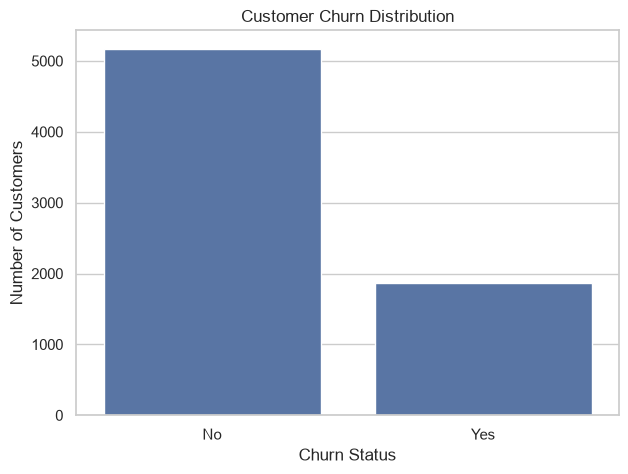

In [3]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

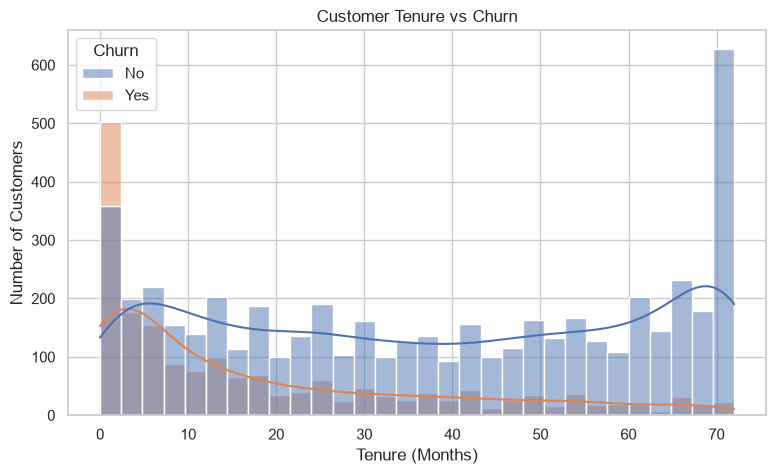

In [4]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    multiple="layer"
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

In [5]:
print(
    df.groupby("Churn")["tenure"].mean()
)

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


In [7]:
contract_percentage = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_percentage)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


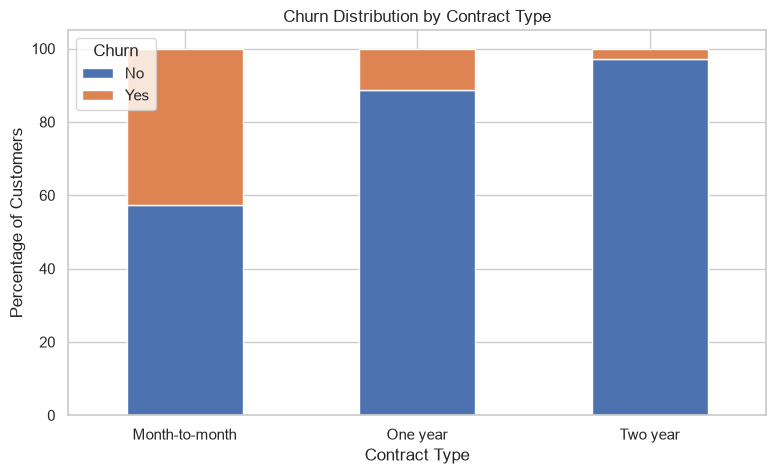

In [8]:
contract_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Churn Distribution by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")

plt.xticks(rotation=0)
plt.show()

In [9]:
monthly_analysis=df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median", "std"])

print(monthly_analysis)

            mean  median        std
Churn                              
No     61.265124  64.425  31.092648
Yes    74.441332  79.650  24.666053


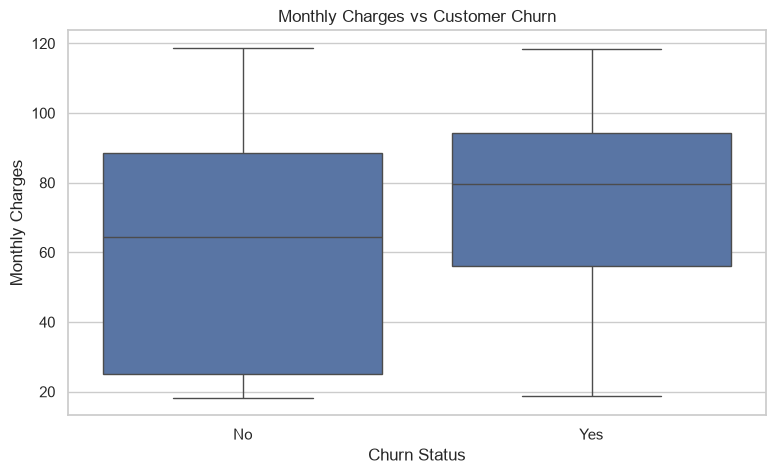

In [10]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.show()

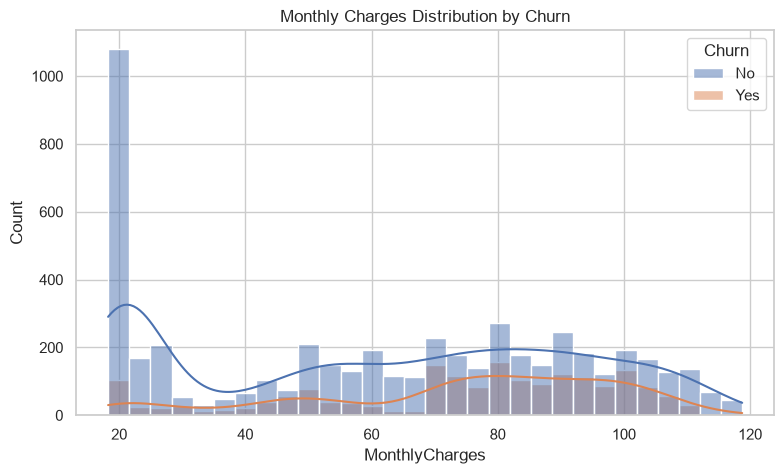

In [11]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    kde=True,
    bins=30
)

plt.title("Monthly Charges Distribution by Churn")
plt.show()

In [12]:
# Divide customers into monthly charge groups

df["ChargeGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 30, 50, 70, 90, 120],
    labels=["0-30", "30-50", "50-70", "70-90", "90-120"]
)

# Calculate churn percentage in each group

charge_churn = pd.crosstab(
    df["ChargeGroup"],
    df["Churn"],
    normalize="index"
) * 100

print(charge_churn)

Churn               No        Yes
ChargeGroup                      
0-30         90.199637   9.800363
30-50        69.195046  30.804954
50-70        79.242033  20.757967
70-90        62.201735  37.798265
90-120       67.222542  32.777458


In [13]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn)

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


In [14]:
print(df["PaymentMethod"].value_counts())

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64


In [15]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn)

Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


In [16]:
print(df["InternetService"].value_counts())

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64


In [17]:
demographic_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

for column in demographic_columns:

    print(f"\nChurn analysis for {column}")

    result = pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    ) * 100

    print(result)


Churn analysis for gender
Churn          No        Yes
gender                      
Female  73.079128  26.920872
Male    73.839662  26.160338

Churn analysis for SeniorCitizen
Churn                 No        Yes
SeniorCitizen                      
0              76.393832  23.606168
1              58.318739  41.681261

Churn analysis for Partner
Churn           No        Yes
Partner                      
No       67.042021  32.957979
Yes      80.335097  19.664903

Churn analysis for Dependents
Churn              No        Yes
Dependents                      
No          68.720860  31.279140
Yes         84.549763  15.450237


In [18]:
service_columns = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

for column in service_columns:

    print(f"\nChurn analysis for {column}")

    result = pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    ) * 100

    print(result.round(2))


Churn analysis for OnlineSecurity
Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61

Churn analysis for OnlineBackup
Churn                   No    Yes
OnlineBackup                     
No                   60.07  39.93
No internet service  92.60   7.40
Yes                  78.47  21.53

Churn analysis for DeviceProtection
Churn                   No    Yes
DeviceProtection                 
No                   60.87  39.13
No internet service  92.60   7.40
Yes                  77.50  22.50

Churn analysis for TechSupport
Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17

Churn analysis for StreamingTV
Churn                   No    Yes
StreamingTV                      
No                   66.48  33.52
No internet service  92.60   7.40
Yes            

In [19]:
from scipy.stats import chi2_contingency

In [20]:
contract_table = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

print(contract_table)

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


In [21]:
chi2, p_value, dof, expected = chi2_contingency(
    contract_table
)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)
print("\nExpected Frequencies:")
print(expected)

Chi-Square Statistic: 1184.5965720837926
P-value: 5.863038300673391e-258
Degrees of Freedom: 2

Expected Frequencies:
[[2846.69175067 1028.30824933]
 [1082.11018032  390.88981968]
 [1245.198069    449.801931  ]]


In [22]:
alpha = 0.05

if p_value < alpha:
    print("Reject the Null Hypothesis")
    print("Contract type is statistically associated with churn.")
else:
    print("Fail to reject the Null Hypothesis")
    print("Insufficient evidence of an association.")

Reject the Null Hypothesis
Contract type is statistically associated with churn.


In [23]:
import numpy as np

n = contract_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(
        contract_table.shape[0] - 1,
        contract_table.shape[1] - 1
    ))
)

print("Cramer's V:", cramers_v)

Cramer's V: 0.4101156965761409


In [24]:
from scipy.stats import chi2_contingency
import numpy as np

categorical_features = [
    "PaymentMethod",
    "InternetService",
    "SeniorCitizen",
    "TechSupport",
    "OnlineSecurity",
    "Partner",
    "Dependents"
]

results = []

for feature in categorical_features:

    table = pd.crosstab(
        df[feature],
        df["Churn"]
    )

    chi2, p, dof, expected = chi2_contingency(table)

    n = table.to_numpy().sum()

    v = np.sqrt(
        chi2 / (
            n * min(
                table.shape[0] - 1,
                table.shape[1] - 1
            )
        )
    )

    results.append({
        "Feature": feature,
        "Chi-Square": chi2,
        "P-Value": p,
        "Cramers V": v
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

        Feature  Chi-Square       P-Value  Cramers V
  PaymentMethod  648.142327 3.682355e-140   0.303359
InternetService  732.309590 9.571788e-160   0.322455
  SeniorCitizen  159.426300  1.510067e-36   0.150453
    TechSupport  828.197068 1.443084e-180   0.342916
 OnlineSecurity  849.998968 2.661150e-185   0.347400
        Partner  158.733382  2.139911e-36   0.150126
     Dependents  189.129249  4.924922e-43   0.163870


In [ ]:
from statsmodels.stats.multitest import multipletests

# Apply Benjamini-Hochberg correction
results_df["Adjusted_P_Value"] = multipletests(
    results_df["P-Value"],
    method="fdr_bh"
)[1]

results_df["Significant"] = (
    results_df["Adjusted_P_Value"] < 0.05
)

print(
    results_df.sort_values(
        "Cramers V",
        ascending=False
    ).to_string(index=False)
)

        Feature  Chi-Square       P-Value  Cramers V  Adjusted_P_Value  Significant
 OnlineSecurity  849.998968 2.661150e-185   0.347400     1.862805e-184         True
    TechSupport  828.197068 1.443084e-180   0.342916     5.050794e-180         True
InternetService  732.309590 9.571788e-160   0.322455     2.233417e-159         True
  PaymentMethod  648.142327 3.682355e-140   0.303359     6.444121e-140         True
     Dependents  189.129249  4.924922e-43   0.163870      6.894890e-43         True
  SeniorCitizen  159.426300  1.510067e-36   0.150453      1.761745e-36         True
        Partner  158.733382  2.139911e-36   0.150126      2.139911e-36         True


: 